<a href="https://colab.research.google.com/github/famub/2026-GP1-02/blob/main/models/3-classes/DenseNet201(3Class).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pre-processing

In [1]:
!pip install kagglehub
import kagglehub
path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity")
print("Path to dataset files:", path)

100%|██████████| 204M/204M [00:12<00:00, 17.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/versions/1


In [2]:
!ls {path}

auto_test  test  train	val


In [3]:
import shutil, os

# The three-class task, as defined by Mohammed et al. (2023), Section 3.1:
# remove grades 0 and 1, keep only grades 2, 3 and 4.
# We copy those three folders into a new place and point the code there.

base3 = "/content/koa_3class"

for split in ["train", "val", "test"]:
    for grade in ["2", "3", "4"]:
        shutil.copytree(f"{path}/{split}/{grade}",
                        f"{base3}/{split}/{grade}",
                        dirs_exist_ok=True)

print("folders:", sorted(os.listdir(f"{base3}/train")))

folders: ['2', '3', '4']


In [4]:
from torchvision import transforms, datasets

base = base3

tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

print("train:", len(train), "| val:", len(val), "| test:", len(test))
print("classes:", train.classes)


train: 2446 | val: 345 | test: 721
classes: ['2', '3', '4']


In [5]:
# only testing
img, label = train[0]
img, label

(tensor([[[-1.2617, -1.1932, -1.1247,  ..., -1.0219, -1.0390, -1.0390],
          [-1.2788, -1.2103, -1.1418,  ..., -1.0390, -1.0390, -1.0562],
          [-1.2617, -1.2103, -1.1589,  ..., -1.0219, -1.0390, -1.0562],
          ...,
          [-0.8164, -0.7308, -0.6965,  ..., -1.9467, -1.9638, -1.9809],
          [-0.8164, -0.7308, -0.6794,  ..., -1.9467, -1.9809, -1.9980],
          [-0.8164, -0.7137, -0.6623,  ..., -1.9467, -1.9638, -1.9809]],
 
         [[-1.1604, -1.0903, -1.0203,  ..., -0.9153, -0.9328, -0.9328],
          [-1.1779, -1.1078, -1.0378,  ..., -0.9328, -0.9328, -0.9503],
          [-1.1604, -1.1078, -1.0553,  ..., -0.9153, -0.9328, -0.9503],
          ...,
          [-0.7052, -0.6176, -0.5826,  ..., -1.8606, -1.8782, -1.8957],
          [-0.7052, -0.6176, -0.5651,  ..., -1.8606, -1.8957, -1.9132],
          [-0.7052, -0.6001, -0.5476,  ..., -1.8606, -1.8782, -1.8957]],
 
         [[-0.9330, -0.8633, -0.7936,  ..., -0.6890, -0.7064, -0.7064],
          [-0.9504, -0.8807,

In [6]:
# validation
class_to_i = train.class_to_idx
class_to_i

{'2': 0, '3': 1, '4': 2}

In [7]:
from collections import Counter

for name, ds in [("train", train), ("val", val), ("test", test)]:
    counts = Counter(ds.targets)
    print(name, {ds.classes[k]: v for k, v in sorted(counts.items())})

train {'2': 1516, '3': 757, '4': 173}
val {'2': 212, '3': 106, '4': 27}
test {'2': 447, '3': 223, '4': 51}


In [8]:
splits = [("train", train), ("val", val), ("test", test)]
total_samples = sum(len(ds.targets) for _, ds in splits)

for name, ds in splits:
    split_size = len(ds.targets)
    split_pct = (split_size / total_samples) * 100

    counts = Counter(ds.targets)
    # calculate class percentages within the split
    class_dist = {ds.classes[k]: f"{v} ({v/split_size*100:.1f}%)" for k, v in sorted(counts.items())}

    print(f"{name:5} | Total: {split_size:4} ({split_pct:.2f}%) | Classes: {class_dist}")

train | Total: 2446 (69.65%) | Classes: {'2': '1516 (62.0%)', '3': '757 (30.9%)', '4': '173 (7.1%)'}
val   | Total:  345 (9.82%) | Classes: {'2': '212 (61.4%)', '3': '106 (30.7%)', '4': '27 (7.8%)'}
test  | Total:  721 (20.53%) | Classes: {'2': '447 (62.0%)', '3': '223 (30.9%)', '4': '51 (7.1%)'}


In [9]:
import torch

counts = Counter(train.targets)
total = sum(counts.values())
n_classes = len(train.classes)                                  # 3 instead of 5
weights = [total / (n_classes * counts[i]) for i in range(n_classes)]
class_weights = torch.tensor(weights, dtype=torch.float)

print("class weights:", [round(w, 2) for w in weights])

class weights: [0.54, 1.08, 4.71]


In [10]:
train_tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224,224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
print("train:", len(train))


train: 2446


In [11]:
from torch.utils.data import DataLoader

val = datasets.ImageFolder(f"{base}/val", transform=tf)
test = datasets.ImageFolder(f"{base}/test", transform=tf)

train_loader = DataLoader(train, batch_size=32, shuffle=True)
val_loader = DataLoader(val, batch_size=32, shuffle=False)
test_loader = DataLoader(test, batch_size=32, shuffle=False)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("labels:", labels[:10])


batch shape: torch.Size([32, 3, 224, 224])
labels: tensor([0, 1, 0, 1, 0, 1, 0, 0, 0, 0])


In [12]:
import cv2
import numpy as np
from PIL import Image
from torch.utils.data import DataLoader

# 1) دالة التنظيف: noise reduction + تحسين التباين
class Denoise:
    def __call__(self, img):
        g = np.array(img.convert("L"))                      # رمادي
        g = cv2.GaussianBlur(g, (3, 3), 0)                  # إزالة الضوضاء
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)  # تحسين التباين
        return Image.fromarray(g)

# 2) pipeline للـ val و test (بدون augmentation)
tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 3) pipeline للـ train (مع augmentation)
train_tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 4) نعيد تحميل الداتا بالـ pipeline الجديد
train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

train_loader = DataLoader(train, batch_size=32, shuffle=True)
val_loader   = DataLoader(val,   batch_size=32, shuffle=False)
test_loader  = DataLoader(test,  batch_size=32, shuffle=False)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("train:", len(train), "| val:", len(val), "| test:", len(test))


batch shape: torch.Size([32, 3, 224, 224])
train: 2446 | val: 345 | test: 721


### Why does the image have 3 channels instead of 1?

Even though your knee X-ray dataset is grayscale, your image tensor shape shows `3` channels because of this line in your pre-processing transforms:

```python
transforms.Grayscale(3)
```

* **Channel Duplication:** This transform takes the single-channel grayscale image and replicates it across 3 identical channels ($R = G = B$).
* **Pre-trained Model Compatibility:** Transfer learning backbones (such as ResNet, EfficientNet, etc.) are pre-trained on ImageNet (RGB datasets) and strictly require a 3-channel input shape. Replicating the channels allows you to use these models without needing to modify their first convolutional layer.

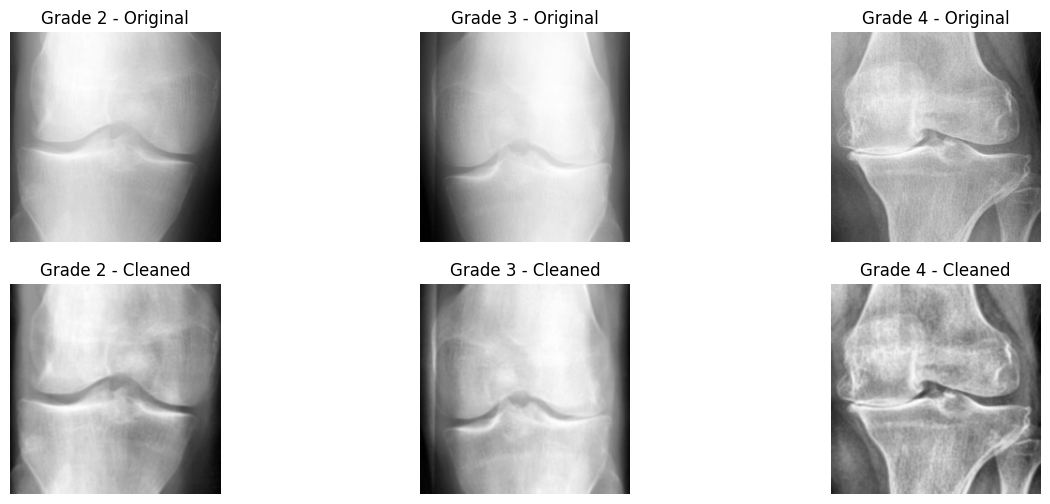

In [13]:
import matplotlib.pyplot as plt
from PIL import Image

n = len(train.classes)                       # 3 instead of 5
fig, axes = plt.subplots(2, n, figsize=(15, 6))
for k in range(n):
    path_k = train.samples[train.targets.index(k)][0]
    original = Image.open(path_k).convert("L")
    cleaned = Denoise()(original)
    grade = train.classes[k]                 # the real KL grade: '2', '3' or '4'
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"Grade {grade} - Original"); axes[0][k].axis("off")
    axes[1][k].imshow(cleaned, cmap="gray"); axes[1][k].set_title(f"Grade {grade} - Cleaned"); axes[1][k].axis("off")
plt.show()

# مو مهم بس عشان اشوف الصور قبل وبعد

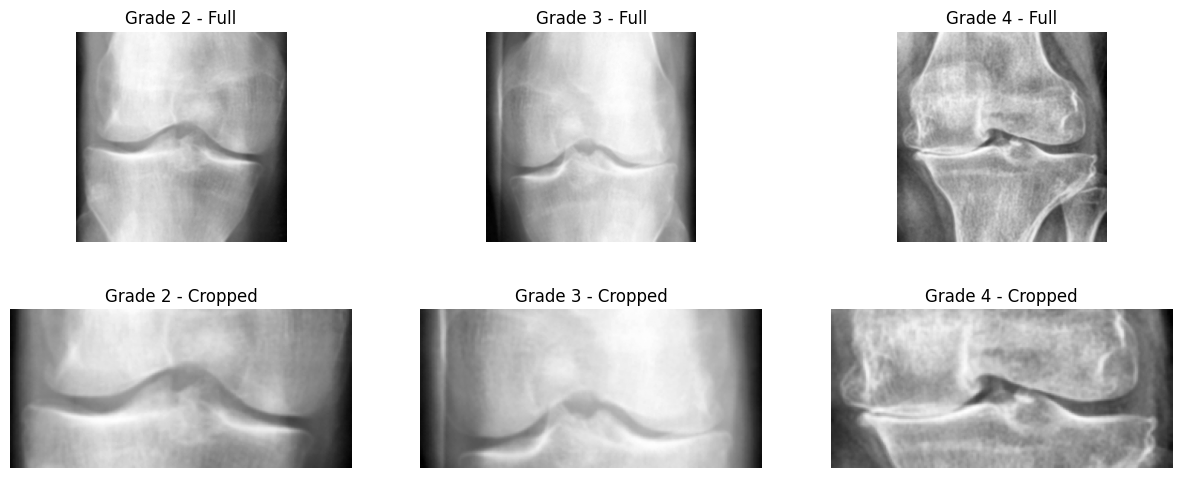

In [14]:
import matplotlib.pyplot as plt
from PIL import Image

def crop_center(img, top=60, bottom=60):
    img = img.resize((224, 224))
    return img.crop((0, top, 224, 224 - bottom))   # 224 x 104

n = len(train.classes)                       # 3 instead of 5
fig, axes = plt.subplots(2, n, figsize=(15, 6))
for k in range(n):
    p = train.samples[train.targets.index(k)][0]
    grade = train.classes[k]                 # the real KL grade: '2', '3' or '4'
    original = Denoise()(Image.open(p).convert("L")).resize((224, 224))
    cropped = crop_center(Denoise()(Image.open(p).convert("L")))
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"Grade {grade} - Full"); axes[0][k].axis("off")
    axes[1][k].imshow(cropped, cmap="gray"); axes[1][k].set_title(f"Grade {grade} - Cropped"); axes[1][k].axis("off")
plt.show()


# Agnostic Code

In [15]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

# Training the model (DenseNet-201)

## Finetuning

In [16]:
import torch.backends.cudnn as cudnn
cudnn.benchmark = True   # hey GPU find the most optimized way to run

In [17]:
def train_step(model,
               data_loader,
               loss_fn,
               optim,
               acc_fn,
               scheduler = None,
               device = device):

  train_loss, train_acc = 0.0, 0.0

  model.to(device)

  model.train() # set model to training mode

  # itera through data/ batches
  for input, label in data_loader:
    input, label = input.to(device), label.to(device)

    # 1. forward
    output = model(input)

    # 2. calculate the loss
    loss = loss_fn(output, label)
    train_loss += loss
    train_acc += acc_fn(y_true=label, y_pred=output.argmax(dim=1))

    # 3. optimizer zero grad
    optim.zero_grad()

    # 4. loss backward
    loss.backward()

    # 5. optimizer step
    optim.step() # to change the weights

    # 6. scheduler step
    if scheduler is not None:
      scheduler.step()

  train_loss /= len(data_loader)
  train_acc /= len(data_loader)
  print(f'Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f}')

In [18]:
def test_step(model,
               data_loader,
               loss_fn,
               acc_fn,
               device = device):

  test_loss, test_acc = 0.0, 0.0

  model.to(device)

  model.eval() # set model to test/ eval mode

  with torch.inference_mode(): # context manager that disable gradient tracking. reduses memory consumption and sped up execution
    for input, label in data_loader:
      input, label = input.to(device), label.to(device)

      # 1. forward
      output = model(input)

      # 2. calculate the loss
      loss = loss_fn(output, label)
      test_loss += loss
      test_acc += acc_fn(y_true=label, y_pred=output.argmax(dim=1))

    test_loss /= len(data_loader)
    test_acc /= len(data_loader)
    print(f'Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}')
    return test_acc

In [19]:
# Calculate accuracy (a classification metric)
def accuracy_fn(y_true, y_pred):
    """Calculates accuracy between truth labels and predictions.

    Args:
        y_true (torch.Tensor): Truth labels for predictions.
        y_pred (torch.Tensor): Predictions to be compared to predictions.

    Returns:
        [torch.float]: Accuracy value between y_true and y_pred, e.g. 78.45
    """
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc


In [20]:
from torchvision import models # to download the pre-trained models
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score

model_ft = models.densenet201(weights=models.DenseNet201_Weights.DEFAULT) # finetuning

num_ftrs = model_ft.classifier.in_features

model_ft.classifier = nn.Linear(num_ftrs, len(train.classes))   # 3 instead of 5

model_ft = model_ft.to(device)

loss_fn = nn.CrossEntropyLoss()

optim = optim.Adam(model_ft.parameters(), lr=0.001) # tweak the entire brain not anly the last layer (fineTuning NOT fixed feature extractor)

acc_fn = accuracy_fn

Downloading: "https://download.pytorch.org/models/densenet201-c1103571.pth" to /root/.cache/torch/hub/checkpoints/densenet201-c1103571.pth


100%|██████████| 77.4M/77.4M [00:00<00:00, 160MB/s]


In [21]:
from sklearn.metrics import f1_score

@torch.inference_mode()
def macro_f1(model, data_loader, device=device):
    """One pass over the loader; returns the macro-F1 of the predictions."""
    model.to(device).eval()
    y_true, y_pred = [], []
    for input, label in data_loader:
        output = model(input.to(device))
        y_pred.extend(output.argmax(dim=1).cpu().tolist())
        y_true.extend(label.tolist())
    return f1_score(y_true, y_pred, average="macro", zero_division=0)

In [22]:
import time
import os
from tqdm.auto import tqdm # import for progress bar

since = time.time()

# Two checkpoints instead of one: the best epoch by accuracy (the original
# behaviour) and the best epoch by macro-F1 (added). A normal folder is used
# instead of TemporaryDirectory so both files survive and can be compared.
save_dir = "/content/checkpoints"
os.makedirs(save_dir, exist_ok=True)
best_acc_path = os.path.join(save_dir, "best_by_acc.pt")
best_f1_path  = os.path.join(save_dir, "best_by_f1.pt")
torch.save(model_ft.state_dict(), best_acc_path)
torch.save(model_ft.state_dict(), best_f1_path)

best_acc = 0.0
best_f1  = 0.0

epochs = 20

for epoch in tqdm(range(epochs)):
    print(f'Epoch: {epoch + 1} / {epochs}')
    print('-' * 10)

    train_step(model=model_ft,
               data_loader=train_loader,
               loss_fn=loss_fn,
               optim=optim,
               acc_fn=acc_fn)

    epoch_acc = test_step(model=model_ft,
                          data_loader=val_loader,
                          loss_fn=loss_fn,
                          acc_fn=acc_fn)

    epoch_f1 = macro_f1(model_ft, val_loader)          # added
    print(f'Val macro-F1: {epoch_f1:.4f}')             # added

    if epoch_acc > best_acc:
        best_acc = epoch_acc
        torch.save(model_ft.state_dict(), best_acc_path)
        print(f'Best model saved with accuracy: {best_acc:.4f}')

    if epoch_f1 > best_f1:                             # added
        best_f1 = epoch_f1
        torch.save(model_ft.state_dict(), best_f1_path)
        print(f'Best model saved with macro-F1: {best_f1:.4f}')

    print()

time_elapsed = time.time() - since
print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
print(f'Best val Acc: {best_acc:.4f} | Best val macro-F1: {best_f1:.4f}')

# Continue with the accuracy-selected model, exactly as the original code did,
# so the evaluation cells below behave the same. The F1 model is compared later.
model_ft.load_state_dict(torch.load(best_acc_path, weights_only=True))

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 1 / 20
----------
Train loss: 0.6772, Train acc: 69.3936
Test loss: 0.6490, Test acc: 75.0795
Val macro-F1: 0.5313
Best model saved with accuracy: 75.0795
Best model saved with macro-F1: 0.5313

Epoch: 2 / 20
----------
Train loss: 0.4847, Train acc: 80.4441
Test loss: 0.4078, Test acc: 82.7273
Val macro-F1: 0.7839
Best model saved with accuracy: 82.7273
Best model saved with macro-F1: 0.7839

Epoch: 3 / 20
----------
Train loss: 0.4170, Train acc: 82.4038
Test loss: 0.4757, Test acc: 82.5114
Val macro-F1: 0.7789

Epoch: 4 / 20
----------
Train loss: 0.4113, Train acc: 83.2676
Test loss: 0.5735, Test acc: 75.0000
Val macro-F1: 0.7320

Epoch: 5 / 20
----------
Train loss: 0.3707, Train acc: 85.9868
Test loss: 0.4790, Test acc: 82.3523
Val macro-F1: 0.7836

Epoch: 6 / 20
----------
Train loss: 0.3701, Train acc: 85.6215
Test loss: 0.4739, Test acc: 83.5227
Val macro-F1: 0.7710
Best model saved with accuracy: 83.5227

Epoch: 7 / 20
----------
Train loss: 0.3483, Train acc: 85.6273


<All keys matched successfully>

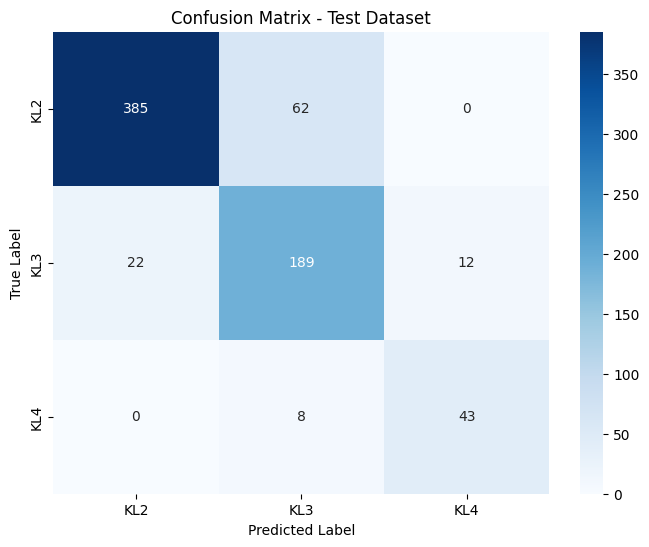

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# The macro-F1 checkpoint is the selected model.
model_ft.load_state_dict(torch.load(best_f1_path, weights_only=True))
y_true, y_pred = predict(model_ft, test_loader)

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(train.classes))))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[f"KL{c}" for c in train.classes],
    yticklabels=[f"KL{c}" for c in train.classes]
)
plt.title('Confusion Matrix - Test Dataset')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [24]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)
import numpy as np

model_ft.eval()
all_preds = []
all_labels = []

with torch.inference_mode():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model_ft(inputs)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(train.classes))),
    target_names=train.classes,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(train.classes)))
))

print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(all_labels, all_preds) * 100, 2),
    "%"
)

              precision    recall  f1-score   support

           2       0.86      0.92      0.89       447
           3       0.76      0.65      0.70       223
           4       0.76      0.82      0.79        51

    accuracy                           0.83       721
   macro avg       0.80      0.80      0.79       721
weighted avg       0.82      0.83      0.82       721

Confusion matrix:
[[410  37   0]
 [ 66 144  13]
 [  1   8  42]]
Balanced accuracy: 79.55 %


In [25]:
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, classification_report

@torch.inference_mode()
def predict(model, data_loader, device=device):
    """One pass over the loader; returns the true labels and the predicted labels."""
    model.to(device).eval()
    y_true, y_pred = [], []
    for input, label in data_loader:
        output = model(input.to(device))
        y_pred.extend(output.argmax(dim=1).cpu().tolist())
        y_true.extend(label.tolist())
    return y_true, y_pred


# The two checkpoints came from different epochs, so this compares the two
# selection rules on the test set: highest validation accuracy vs highest
# validation macro-F1.
for name, checkpoint in [("best by accuracy", best_acc_path),
                         ("best by macro-F1", best_f1_path)]:
    model_ft.load_state_dict(torch.load(checkpoint, weights_only=True))
    y_true, y_pred = predict(model_ft, test_loader)

    print(f"===== {name} =====")
    print("test accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("test macro-F1 :", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4))
    print("test QWK      :", round(cohen_kappa_score(y_true, y_pred, weights="quadratic"), 4))
    print(classification_report(y_true, y_pred,
                                labels=list(range(len(train.classes))),
                                target_names=train.classes, zero_division=0))

===== best by accuracy =====
test accuracy : 0.8266
test macro-F1 : 0.793
test QWK      : 0.774
              precision    recall  f1-score   support

           2       0.86      0.92      0.89       447
           3       0.76      0.65      0.70       223
           4       0.76      0.82      0.79        51

    accuracy                           0.83       721
   macro avg       0.80      0.80      0.79       721
weighted avg       0.82      0.83      0.82       721

===== best by macro-F1 =====
test accuracy : 0.8558
test macro-F1 : 0.8324
test QWK      : 0.8186
              precision    recall  f1-score   support

           2       0.95      0.86      0.90       447
           3       0.73      0.85      0.78       223
           4       0.78      0.84      0.81        51

    accuracy                           0.86       721
   macro avg       0.82      0.85      0.83       721
weighted avg       0.87      0.86      0.86       721



In [28]:
import os
from tqdm.auto import tqdm
import torch.optim as torch_optim


def run_experiment(lr, tag, epochs=20, weight_decay=0.0):          # changed
    """Train a fresh DenseNet-201 at the given learning rate.

    Keeps two checkpoints, the best epoch by validation accuracy and the best by
    validation macro-F1. Returns the model and the two checkpoint paths.
    """
    model = models.densenet201(weights=models.DenseNet201_Weights.DEFAULT)
    model.classifier = nn.Linear(model.classifier.in_features, len(train.classes))
    model = model.to(device)

    loss = nn.CrossEntropyLoss()
    opt = torch_optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)   # changed

    folder = f"/content/{tag}"
    os.makedirs(folder, exist_ok=True)
    acc_path, f1_path = f"{folder}/best_by_acc.pt", f"{folder}/best_by_f1.pt"
    best_acc, best_f1 = 0.0, 0.0

    for epoch in tqdm(range(epochs)):
        print(f'Epoch: {epoch + 1} / {epochs}')
        print('-' * 10)

        train_step(model=model, data_loader=train_loader, loss_fn=loss, optim=opt, acc_fn=acc_fn)
        epoch_acc = test_step(model=model, data_loader=val_loader, loss_fn=loss, acc_fn=acc_fn)
        epoch_f1 = macro_f1(model, val_loader)
        print(f'Val macro-F1: {epoch_f1:.4f}')

        if epoch_acc > best_acc:
            best_acc = epoch_acc
            torch.save(model.state_dict(), acc_path)
            print(f'Best model saved with accuracy: {best_acc:.4f}')

        if epoch_f1 > best_f1:
            best_f1 = epoch_f1
            torch.save(model.state_dict(), f1_path)
            print(f'Best model saved with macro-F1: {best_f1:.4f}')
        print()

    print(f'Best val Acc: {best_acc:.4f} | Best val macro-F1: {best_f1:.4f}')
    return model, acc_path, f1_path

In [23]:
# Experiment 02: same as experiment 01, with the learning rate lowered to 3e-4.
model_02, acc_02, f1_02 = run_experiment(lr=3e-4, tag="exp02")

report(model_02, acc_02, "exp 02 - best by accuracy")
report(model_02, f1_02, "exp 02 - best by macro-F1")

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 1 / 20
----------
Train loss: 0.6403, Train acc: 71.5619
Test loss: 0.4979, Test acc: 78.5114
Val macro-F1: 0.7283
Best model saved with accuracy: 78.5114
Best model saved with macro-F1: 0.7283

Epoch: 2 / 20
----------
Train loss: 0.3933, Train acc: 84.0561
Test loss: 0.4876, Test acc: 81.3409
Val macro-F1: 0.7892
Best model saved with accuracy: 81.3409
Best model saved with macro-F1: 0.7892

Epoch: 3 / 20
----------
Train loss: 0.3509, Train acc: 86.0853
Test loss: 0.5277, Test acc: 82.1591
Val macro-F1: 0.7765
Best model saved with accuracy: 82.1591

Epoch: 4 / 20
----------
Train loss: 0.2935, Train acc: 87.9116
Test loss: 0.4045, Test acc: 82.6818
Val macro-F1: 0.8178
Best model saved with accuracy: 82.6818
Best model saved with macro-F1: 0.8178

Epoch: 5 / 20
----------
Train loss: 0.2770, Train acc: 89.9814
Test loss: 0.3560, Test acc: 86.1250
Val macro-F1: 0.8526
Best model saved with accuracy: 86.1250
Best model saved with macro-F1: 0.8526

Epoch: 6 / 20
----------
Trai

NameError: name 'predict' is not defined

In [24]:
@torch.inference_mode()
def predict(model, data_loader, device=device):
    """One pass over the loader; returns the true labels and the predicted labels."""
    model.to(device).eval()
    y_true, y_pred = [], []
    for input, label in data_loader:
        output = model(input.to(device))
        y_pred.extend(output.argmax(dim=1).cpu().tolist())
        y_true.extend(label.tolist())
    return y_true, y_pred

In [26]:
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score,
                             classification_report, confusion_matrix)

In [27]:
report(model_02, acc_02, "exp 02 - best by accuracy")
report(model_02, f1_02, "exp 02 - best by macro-F1")

===== exp 02 - best by accuracy =====
test accuracy : 0.8599
test macro-F1 : 0.8282
test QWK      : 0.8186
              precision    recall  f1-score   support

           2       0.89      0.93      0.91       447
           3       0.80      0.73      0.76       223
           4       0.82      0.80      0.81        51

    accuracy                           0.86       721
   macro avg       0.84      0.82      0.83       721
weighted avg       0.86      0.86      0.86       721

===== exp 02 - best by macro-F1 =====
test accuracy : 0.8599
test macro-F1 : 0.8282
test QWK      : 0.8186
              precision    recall  f1-score   support

           2       0.89      0.93      0.91       447
           3       0.80      0.73      0.76       223
           4       0.82      0.80      0.81        51

    accuracy                           0.86       721
   macro avg       0.84      0.82      0.83       721
weighted avg       0.86      0.86      0.86       721



In [29]:
# Experiment 03: same as experiment 02, with AdamW and weight decay 0.05.
model_03, acc_03, f1_03 = run_experiment(lr=3e-4, tag="exp03", weight_decay=0.05)

report(model_03, acc_03, "exp 03 - best by accuracy")
report(model_03, f1_03, "exp 03 - best by macro-F1")

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 1 / 20
----------
Train loss: 0.5867, Train acc: 74.8667
Test loss: 0.4401, Test acc: 82.0227
Val macro-F1: 0.7778
Best model saved with accuracy: 82.0227
Best model saved with macro-F1: 0.7778

Epoch: 2 / 20
----------
Train loss: 0.3946, Train acc: 83.4474
Test loss: 0.3446, Test acc: 85.5114
Val macro-F1: 0.8589
Best model saved with accuracy: 85.5114
Best model saved with macro-F1: 0.8589

Epoch: 3 / 20
----------
Train loss: 0.3116, Train acc: 86.8159
Test loss: 0.3617, Test acc: 86.8636
Val macro-F1: 0.8383
Best model saved with accuracy: 86.8636

Epoch: 4 / 20
----------
Train loss: 0.2697, Train acc: 88.9205
Test loss: 0.4582, Test acc: 86.0909
Val macro-F1: 0.8181

Epoch: 5 / 20
----------
Train loss: 0.2393, Train acc: 90.6308
Test loss: 0.4256, Test acc: 86.3295
Val macro-F1: 0.8376

Epoch: 6 / 20
----------
Train loss: 0.2114, Train acc: 91.9643
Test loss: 0.4049, Test acc: 86.2841
Val macro-F1: 0.8501

Epoch: 7 / 20
----------
Train loss: 0.1621, Train acc: 93.2398


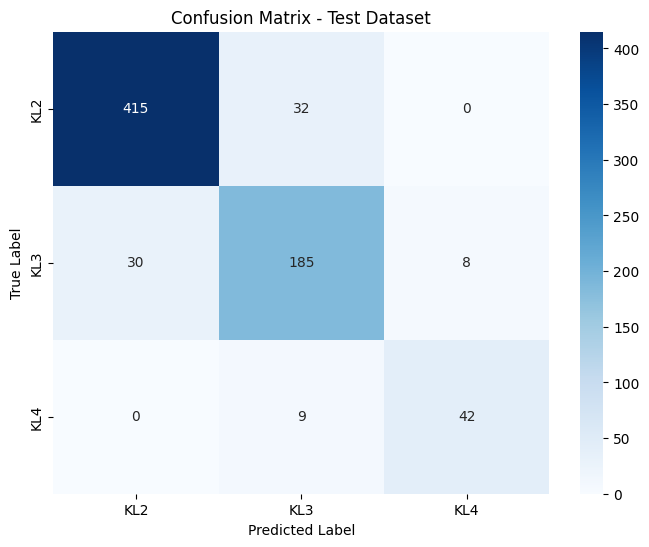

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

model_03.load_state_dict(torch.load(f1_03, weights_only=True))
y_true, y_pred = predict(model_03, test_loader)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["KL2", "KL3", "KL4"],
            yticklabels=["KL2", "KL3", "KL4"])
plt.title('Confusion Matrix - Test Dataset')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()